<a href="https://colab.research.google.com/github/gmauricio-toledo/math-ML/blob/main/Tareas/TC-11%20-%20CNN_Pneumonia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clasificación Binaria con Redes Neuronales Convolucionales (PneumoniaMNIST)

En esta práctica vas a comparar el desempeño de un perceptrón multicapa tradicional frente a dos arquitecturas convolucionales distintas para detectar neumonía en radiografías de tórax. Trabajarás directamente con los arreglos en memoria.

---

## 1. Carga y exploración de datos

1. Instala la librería `medmnist` y descarga las particiones de entrenamiento (`train`), validación (`val`) y prueba (`test`) de `PneumoniaMNIST`.
2. Extrae las imágenes y las etiquetas directamente como arreglos de NumPy en memoria (`imgs` y `labels`).
3. Verifica las dimensiones de cada arreglo, el tipo de dato, el rango de valores de los píxeles y visualiza algunas muestras de cada clase.
4. Analiza el balance de clases en los tres subconjuntos. Comenta brevemente cómo afecta esta distribución a la elección de la métrica de evaluación.

## 2. Preprocesamiento

1. Re-escala los valores de los píxeles si es necesario para estabilizar el entrenamiento.
2. Ajusta las dimensiones de los tensores de entrada según lo que requiera cada arquitectura (vector aplanado para el modelo denso vs. tensor con dimensión de canal para las capas convolucionales).
3. Asegúrate de que las etiquetas tengan la forma y el tipo de dato adecuados para la función de pérdida binaria que vas a utilizar.

## 3. Definición y entrenamiento de modelos

Vas a diseñar, compilar y entrenar tres modelos distintos. En los tres casos, define la capa de salida y la función de pérdida correspondientes a un problema de clasificación binaria, y utiliza un callback de `EarlyStopping` monitoreando la métrica de tu elección sobre el conjunto de validación (asegúrate de restaurar los mejores pesos al finalizar).

* Modelo 1 (Baseline MLP): Implementa una red neuronal completamente conectada (sin capas convolucionales) que sirva como punto de referencia.
* Modelo 2 (CNN 1): Implementa una primera arquitectura convolucional con varias capas convolucionales y *pooling*, seguida de su bloque denso de clasificación.
* Modelo 3 (CNN 2): Implementa una segunda arquitectura convolucional distinta a la anterior (modifica la profundidad, el número de filtros, el tamaño de los kernels, o incorpora técnicas de regularización/normalización como `BatchNormalization` o `Dropout`).

## 4. Evaluación y comparación

1. Evalúa los tres modelos entrenados utilizando el conjunto de prueba (`test`), el cual no debe haberse usado durante el entrenamiento ni para el `EarlyStopping`.
2. Reporta en una tabla comparativa el valor de la métrica elegida obtenida en el conjunto de prueba por cada modelo.
3. Calcula y grafica la matriz de confusión para cada uno de los tres modelos sobre el conjunto de prueba.
4. Concluye qué arquitectura obtuvo el mejor desempeño, analiza los tipos de error que comete cada modelo (falsos positivos frente a falsos negativos) y explica por qué las arquitecturas convolucionales superan o difieren del modelo baseline en este tipo de imágenes.

In [1]:
!pip install medmnist

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [medmnist]


In [7]:

import medmnist
from medmnist import PneumoniaMNIST # o BreastMNIST

# Descarga y carga directamente en memoria
train_data = PneumoniaMNIST(split='train', download=True)
test_data  = PneumoniaMNIST(split='test', download=True)
val_data  = PneumoniaMNIST(split='val', download=True)

# Arreglos de NumPy listos para usar: (N, 28, 28) y (N, 1)
X_train, y_train = train_data.imgs, train_data.labels.squeeze()
X_test, y_test = test_data.imgs, test_data.labels.squeeze()
X_val, y_val = val_data.imgs, val_data.labels.squeeze()

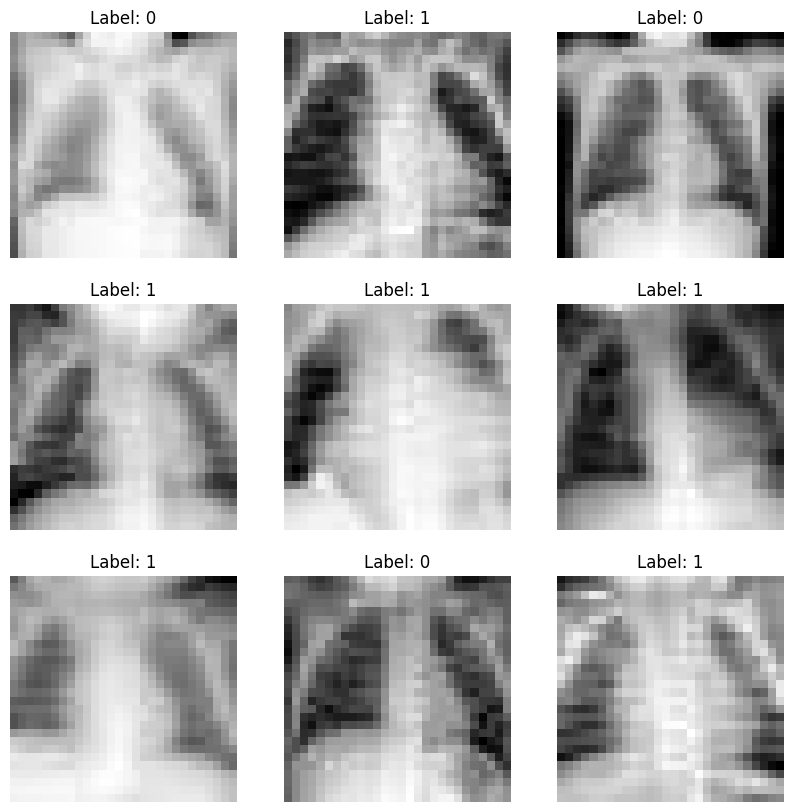

In [6]:
import matplotlib.pyplot as plt
import numpy as np

random_idxs = np.random.choice(len(X_train), 9)

fig, axs = plt.subplots(3, 3, figsize=(10, 10))
for i, idx in enumerate(random_idxs):
    img = X_train[idx]
    label = y_train[idx]
    axs[i // 3, i % 3].imshow(img, cmap='gray')
    axs[i // 3, i % 3].set_title(f'Label: {label}')
    axs[i // 3, i % 3].axis('off')

plt.show()